In [4]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.metrics import mean_squared_error

In [5]:
df=pd.read_csv('insurance.csv')

In [21]:
x=df.drop(columns=['charges'])
y=df['charges']

x=pd.get_dummies(x, columns=['region'], drop_first=False, dtype=int)   # one hot encoding
x['smoker']=x['smoker'].map({'yes':1, 'no':0})
x['sex']=x['sex'].map({'male':1, 'female':0})

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42)


lass=[0,0.1,0.0001,0.2,1,1.5,2,2.5,1.3]
ms=[]
for i in lass:
    lasso_reg=Lasso(alpha=i)
    lasso_reg.fit(x_train,y_train)
    y_pred= lasso_reg.predict(x_test)
    
    mse=mean_squared_error(y_test, y_pred)
    
    print('The mse is : ', mse)

    ms.append(mse)

The mse is :  33596945.380100235
The mse is :  33597180.375486486
The mse is :  33596916.115689605
The mse is :  33597445.098104715
The mse is :  33605932.26390232
The mse is :  33610484.93988681
The mse is :  33615034.16817718
The mse is :  33619587.86797106
The mse is :  33608655.00337466


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)


In [22]:
ms

[33596945.380100235,
 33597180.375486486,
 33596916.115689605,
 33597445.098104715,
 33605932.26390232,
 33610484.93988681,
 33615034.16817718,
 33619587.86797106,
 33608655.00337466]

<Axes: >

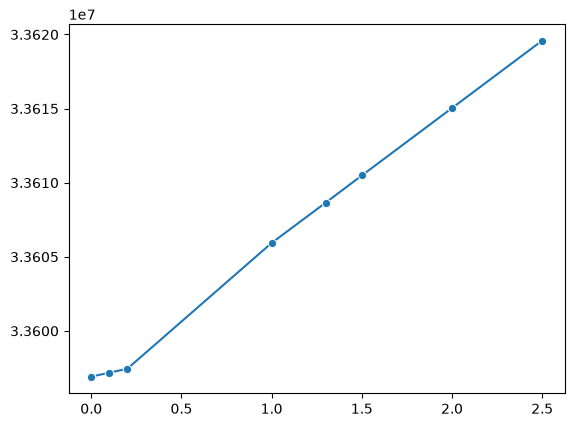

In [23]:
import seaborn as sns
sns.lineplot(x=lass, y=ms, marker='o')

In [28]:
# Using lassoCV
from sklearn.linear_model import LassoCV
a=[0,0.1,0.0001,0.2,1,1.5,2,2.5,1.3]
lasso_model=LassoCV(
    alphas=a,
    cv=5,
    max_iter=1000,
    random_state=42
)
lasso_model.fit(x_train, y_train)
print('the best alpha is :', lasso_model.alpha_)
y_pred=lasso_model.predict(x_test)

mse=mean_squared_error(y_test,y_pred)
print('the value of mse is: ', mse)

the best alpha is : 2.5
the value of mse is:  33619587.86797106
